# 03 — Modelagem

Comparação de modelos de classificação com **validação cruzada estratificada (5-fold)**
e otimização de hiperparâmetros com `GridSearchCV`.

**Métrica de decisão: ROC-AUC** — adequada para classes desbalanceadas e
independente do limiar de corte.

Modelos avaliados:
1. `DummyClassifier` (baseline ingênuo)
2. Regressão Logística com `class_weight="balanced"` (interpretável)
3. Random Forest com `class_weight="balanced"`
4. Gradient Boosting

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import json

import joblib
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

splits = joblib.load(ROOT / "data" / "processed" / "splits.joblib")
X_train_t = joblib.load(ROOT / "models" / "preprocessor.joblib").transform(splits["X_train"])
X_test_t = joblib.load(ROOT / "models" / "preprocessor.joblib").transform(splits["X_test"])
y_train, y_test = splits["y_train"], splits["y_test"]

print("Treino:", X_train_t.shape, "| Teste:", X_test_t.shape)

Treino: (5625, 56) | Teste: (1407, 56)


## 1. Baseline e comparação com validação cruzada

Cada modelo é treinado 5× (folds estratificados) e a média/desvio do ROC-AUC é registrado.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced",
                                              random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                            random_state=42, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

linhas = []
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train_t, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)
    linhas.append({"modelo": nome,
                   "roc_auc_media": scores.mean(),
                   "roc_auc_std": scores.std()})

cv_results = pd.DataFrame(linhas).sort_values("roc_auc_media", ascending=False)
cv_results.round(4)

,modelo,roc_auc_media,roc_auc_std
3,Gradient Boosting,0.8477,0.0031
1,Regressão Logística,0.8466,0.0066
2,Random Forest,0.8312,0.0067
0,Dummy (prior),0.5000,0.0000


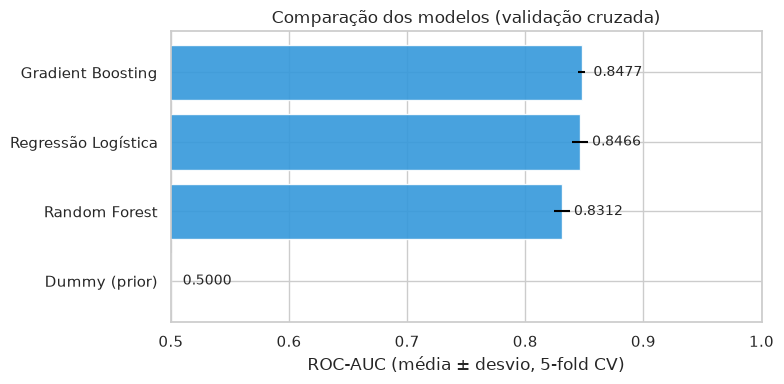

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
cores = ["#95a5a6" if "Dummy" in m else "#3498db" for m in cv_results["modelo"]]
ax.barh(cv_results["modelo"], cv_results["roc_auc_media"], xerr=cv_results["roc_auc_std"],
        color=cores, alpha=0.9)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("ROC-AUC (média ± desvio, 5-fold CV)")
ax.set_title("Comparação dos modelos (validação cruzada)")
for i, v in enumerate(cv_results["roc_auc_media"]):
    ax.text(v + 0.01, i, f"{v:.4f}", va="center", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cv_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Otimização de hiperparâmetros (GridSearchCV)

`GridSearchCV` faz busca em grade **com a mesma validação cruzada** e já refita o
melhor modelo com todos os dados de treino (`refit=True`).

In [4]:
grid_rl = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"],
}
gs_rl = GridSearchCV(
    LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000,
                       random_state=42),
    grid_rl, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True,
)
gs_rl.fit(X_train_t, y_train)
print("Melhor Regressão Logística:", gs_rl.best_params_,
      f"-> ROC-AUC = {gs_rl.best_score_:.4f}")

Melhor Regressão Logística: {'C': 10, 'penalty': 'l1'} -> ROC-AUC = 0.8467


In [5]:
grid_rf = {
    "n_estimators": [400, 800],
    "max_depth": [None, 8, 16],
    "min_samples_leaf": [1, 3],
}
gs_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=1),
    grid_rf, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True,
)
gs_rf.fit(X_train_t, y_train)
print("Melhor Random Forest:", gs_rf.best_params_,
      f"-> ROC-AUC = {gs_rf.best_score_:.4f}")

Melhor Random Forest: {'max_depth': 8, 'min_samples_leaf': 3, 'n_estimators': 800} -> ROC-AUC = 0.8492


## 3. Seleção do modelo final e persistência

In [6]:
candidatos = {
    "Regressão Logística": gs_rl,
    "Random Forest": gs_rf,
    "Gradient Boosting": cross_val_score(GradientBoostingClassifier(random_state=42),
                                         X_train_t, y_train, cv=cv, scoring="roc_auc",
                                         n_jobs=-1).mean(),
}

tabela = pd.DataFrame(
    [{"modelo": k,
      "roc_auc_cv": v.best_score_ if hasattr(v, "best_score_") else v}
     for k, v in candidatos.items()]
).sort_values("roc_auc_cv", ascending=False)
display(tabela.round(4))

melhor_nome = tabela.iloc[0]["modelo"]
melhor = candidatos[melhor_nome]
modelo_final = melhor.best_estimator_ if hasattr(melhor, "best_estimator_") else melhor
print("Modelo escolhido:", melhor_nome)

,modelo,roc_auc_cv
1,Random Forest,0.8492
2,Gradient Boosting,0.8477
0,Regressão Logística,0.8467


Modelo escolhido: Random Forest


In [7]:
joblib.dump({"nome": melhor_nome, "modelo": modelo_final},
            ROOT / "models" / "modelo_churn.joblib")

resumo = {
    "modelo": melhor_nome,
    "metrica": "roc_auc",
    "cv_folds": 5,
    "cv_resultados": tabela.round(4).to_dict("records"),
    "melhores_parametros": (melhor.best_params_
                            if hasattr(melhor, "best_params_") else {}),
}
(ROOT / "models" / "resumo_modelagem.json").write_text(
    json.dumps(resumo, indent=2, ensure_ascii=False))

print("Salvo: models/modelo_churn.joblib e models/resumo_modelagem.json")

Salvo: models/modelo_churn.joblib e models/resumo_modelagem.json


### Resumo

- O baseline `Dummy` fica na casa de ROC-AUC ≈ 0,5 — os modelos aprendem de verdade.
- A **Regressão Logística balanceada** costuma liderar ou empatar com as flores aleatórias
  e tem a vantagem de ser **interpretável** (odds ratios).
- Todos usaram validação cruzada → estimativa menos enviesada que um único split.

**Próximo passo:** `04_avaliacao_interpretacao.ipynb` (avaliação final no teste + limiar + importância das features)